In [5]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
%matplotlib inline
from matplotlib.pylab import rcParams
rcParams['figure.figsize'] = 15, 6
from datetime import datetime
from pmdarima.arima import auto_arima

In [8]:
data = pd.read_csv('AirPassengers.csv', parse_dates = ['Month'],
                  index_col = 'Month', date_format = '%Y-%m')

In [9]:
data

,#Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1960-08-01,606
1960-09-01,508
1960-10-01,461


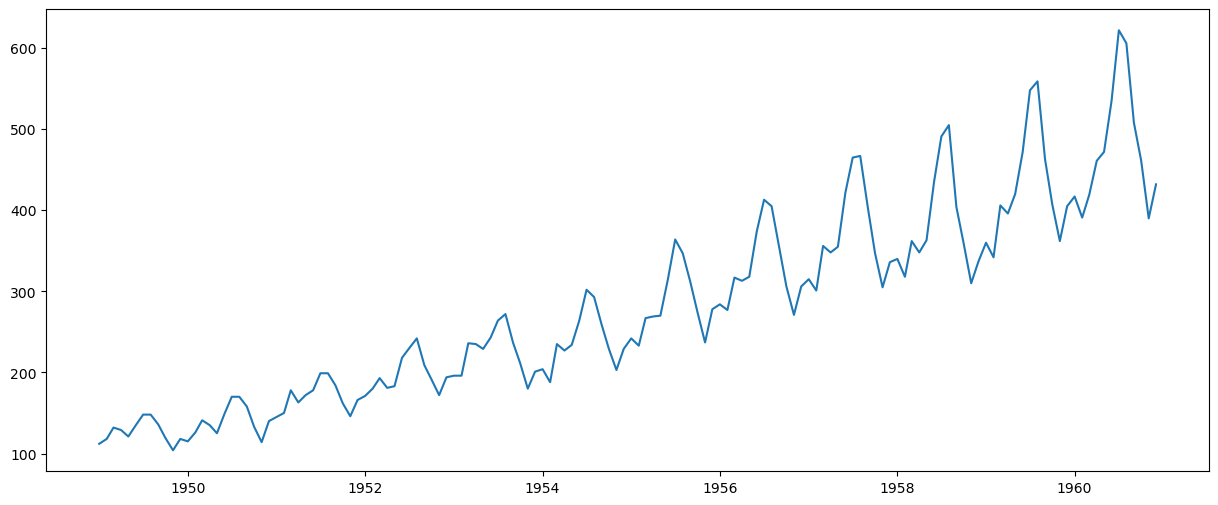

In [10]:
plt.plot(data)

In [13]:
stepwise_model = auto_arima(data, start_p=1, start_q=1, start_d=0, start_P=0, max_p=6, max_q=6, m=12, seasonal=True, trace=True, stepwise=False)

 ARIMA(0,1,0)(0,1,0)[12]             : AIC=1031.508, Time=0.02 sec
 ARIMA(0,1,0)(0,1,1)[12]             : AIC=1030.752, Time=0.07 sec
 ARIMA(0,1,0)(0,1,2)[12]             : AIC=1032.276, Time=0.98 sec
 ARIMA(0,1,0)(1,1,0)[12]             : AIC=1030.408, Time=0.04 sec
 ARIMA(0,1,0)(1,1,1)[12]             : AIC=1032.128, Time=0.14 sec
 ARIMA(0,1,0)(1,1,2)[12]             : AIC=1034.096, Time=0.29 sec
 ARIMA(0,1,0)(2,1,0)[12]             : AIC=1032.120, Time=0.10 sec
 ARIMA(0,1,0)(2,1,1)[12]             : AIC=inf, Time=0.92 sec
 ARIMA(0,1,0)(2,1,2)[12]             : AIC=inf, Time=1.02 sec
 ARIMA(0,1,1)(0,1,0)[12]             : AIC=1020.639, Time=0.16 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=1021.003, Time=0.10 sec
 ARIMA(0,1,1)(0,1,2)[12]             : AIC=1019.494, Time=0.24 sec
 ARIMA(0,1,1)(1,1,0)[12]             : AIC=1020.425, Time=0.07 sec
 ARIMA(0,1,1)(1,1,1)[12]             : AIC=1020.327, Time=0.23 sec
 ARIMA(0,1,1)(1,1,2)[12]             : AIC=1012.991, Time=0.68 sec
 ARIM

In [14]:
#Com stepwise: 1019.1780567487203
#Sem stepwise: 1012.9907964624293
print(stepwise_model.aic())

1012.9907964624293


In [21]:
train = data.loc['1949-01-01':'1959-12-01']
test = data.loc['1960-01-01':]

In [22]:
train

,#Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1959-08-01,559
1959-09-01,463
1959-10-01,407


In [23]:
test

,#Passengers
Month,
1960-01-01,417
1960-02-01,391
1960-03-01,419
1960-04-01,461
1960-05-01,472
1960-06-01,535
1960-07-01,622
1960-08-01,606
1960-09-01,508


In [18]:
stepwise_model.fit(train)

,order,"(0, ...)"
,seasonal_order,"(1, ...)"
,start_params,None
,method,'lbfgs'
,maxiter,50
,suppress_warnings,True
,out_of_sample_size,0
,scoring,'mse'
,scoring_args,{}
,trend,None
,with_intercept,False


In [46]:
future_forecast = stepwise_model.predict(n_periods=12)

In [47]:
future_forecast

1960-01-01    420.234415
1960-02-01    398.443062
1960-03-01    461.900087
1960-04-01    450.680791
1960-05-01    473.997289
1960-06-01    537.933005
1960-07-01    612.252567
1960-08-01    623.604345
1960-09-01    520.168726
1960-10-01    462.311032
1960-11-01    412.914352
1960-12-01    453.735711
Freq: MS, dtype: float64

In [48]:
future_forecast = pd.DataFrame(future_forecast, index = test.index, columns=["#Passengers"])

<Axes: xlabel='Month'>

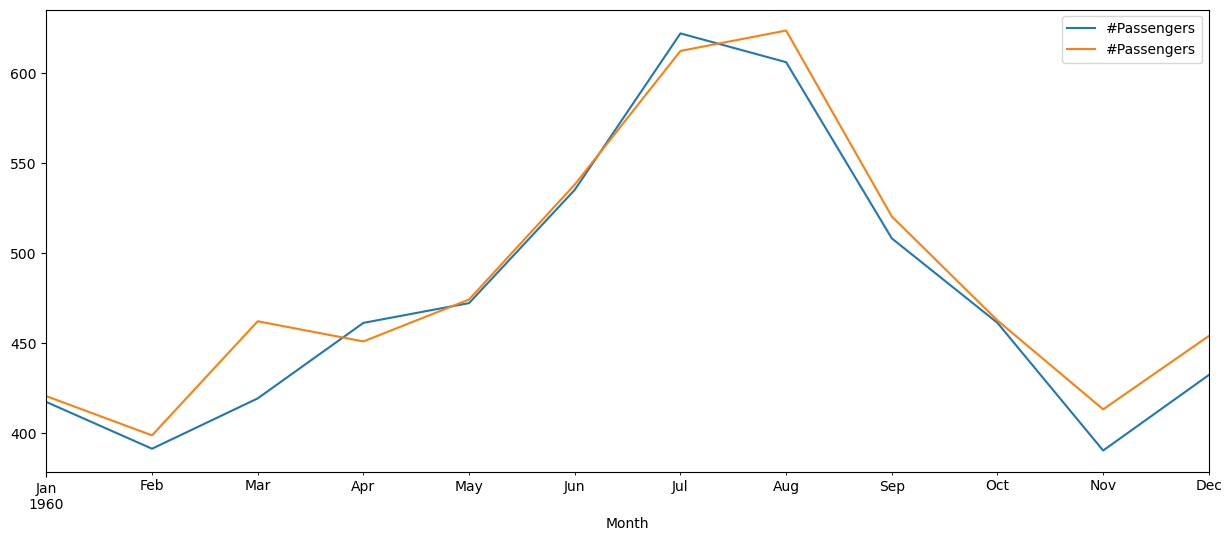

In [49]:
pd.concat([test, future_forecast], axis = 1).plot()

<Axes: xlabel='Month'>

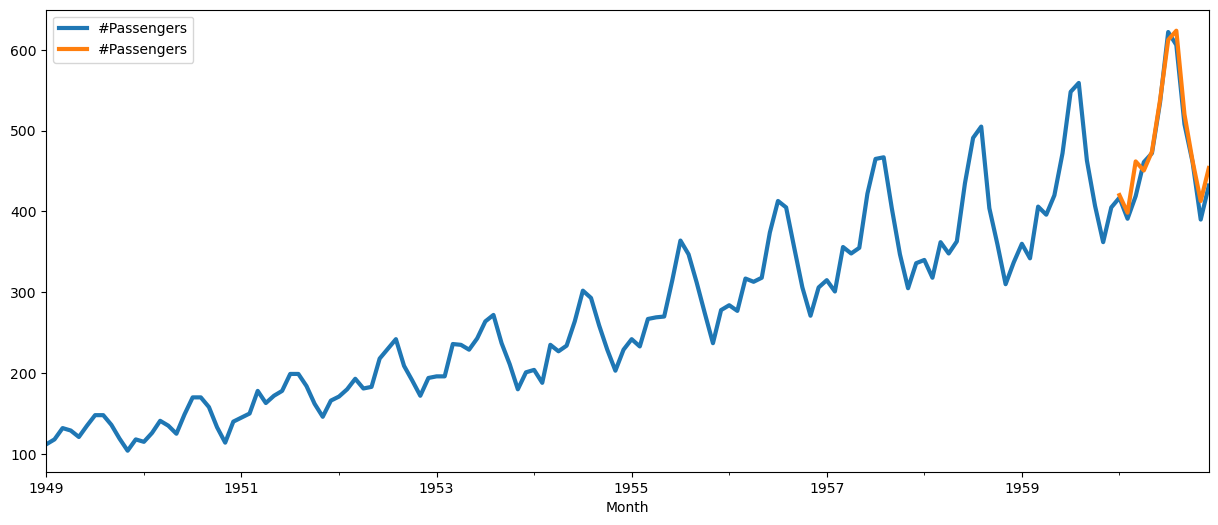

In [45]:
pd.concat([data, future_forecast], axis = 1).plot(linewidth = 3)